# 04 Creep-event detection, size, extent and the slip budget

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. The bootstraps and the per-crossing fits take ~5 min.
```

**What this notebook does.** This is the only place event dates are defined:
every later notebook reads `creep_events.csv` from here.

1. **Detect** the events on the stacked fault-parallel series of the Tule Pond
   section (crossings within 2 km of the section centre): remove rate + annual
   cycle, run a matched filter for a step (mean of the next 3 epochs minus the
   previous 3), flag where it exceeds 3 robust sigma. Oakland (COZ1) is run the
   same way as the positive control: its creepmeter records the same events.
2. **Size and timing** from ONE joint model per stack (linear + annual + a step
   per event), grid-searching each onset over the acquisition epochs. The onset
   window is one acquisition interval. Amplitude CIs are block bootstraps.
3. **Along strike**: the same joint model at every crossing with the onsets
   held fixed gives per-event slip profiles, the inter-event (secular) rate
   and the event-driven fraction of slip.
4. **Section lengths**: (a) the length of fault hosting the events, where the
   cumulative event slip departs from zero (threshold from the flank scatter);
   (b) the width of the peak slip zone at 75% and 90% of the peak fraction.
5. **Band stack**: the joint model on the mean of the peak-zone crossings, the
   numbers the paper quotes for the five events.
6. **Slip budget**: secular + event-driven rate against the alignment arrays
   (refit over the InSAR window, and their whole-record rates) and creepmeters.
7. Recurrence intervals; Bo Xie's relocated seismicity and the repeating
   earthquakes near the section.

Ported from `Hayward_DISP-S1/analysis/run12_detect_events.py`,
`run14_event_fraction.py`, `hayward_creep/plotting/plot_event_summary.py` and
`plot_slip_budget.py`. One stream everywhere: 30 to 150 m, coherence 0.7.

**Outputs** (`outputs/04_event_detection/`): `creep_events.csv`,
`creepmeter_events_COZ1.csv`, `event_fraction_by_crossing.csv`,
`section_lengths.csv`, `band_stack_<band>.csv`, `slip_budget_by_crossing.csv`,
`aa_rates.csv`, `04_events_stats.txt`, registry rows `04_*`.

**Figures**: detection QC (supplement), Fig 1 (rotated map, hovmoller,
per-event profiles, rate budget, band stack), the slip budget along the fault.

**What to check.** Five Tule Pond events, two years apart, each about 10 mm on
the band stack; the two large COZ1 events also seen by its creepmeter; a
fraction of ~80% event-driven inside the section and ~10% outside; the budget
closing (secular + event-driven ~ the long-term array rate of ~6.5 mm/yr).

In [1]:
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, segments, creepmeters, params, coh_timeseries,
                                dist_min, dist_max, rate_smooth_km, paths_out, repo_dir)

import numpy as np
import pandas as pd
import pyproj
import xarray as xr
import matplotlib.pyplot as plt
import pygmt

## Constants

In [2]:
notebook = "04_event_detection"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the detector
stack_half_km = 2.0     # half-width of the peak-slip stack about the section centre; a whole-section
#                         average dilutes the transient with non-slipping fault
win_n = 3               # epochs each side in the matched filter (3 x ~6 d: sharp against months-long wander)
k_sigma = 3.0           # detection threshold in robust sigma of the statistic
merge_yr = 0.15         # flags closer than this are one event
onset_search_yr = 0.10  # grid-search the onset over acquisition epochs within this of the detection
nboot, block_years, seed = 2000, 1.0, 0    # block bootstrap for the amplitude CIs

# along strike
min_epoch_frac = 0.5    # a crossing needs >50% finite epochs to be fitted
smooth_km = 0.4         # along-fault smoothing of the profiles (gap-preserving)
total_floor_mm = 1.0    # |total slip| below this: fraction undefined
band_fracs = (0.75, 0.90)   # the peak slip zone: fraction >= this x its local peak (Dani picks one)
band_main = 0.90            # the band the figures draw and the paper quotes
flank_km = ((52.0, 56.0), (64.0, 68.0))   # flanks used for the creep-length threshold (Tule Pond)
seis_max_dist_km = 2.0  # seismicity and repeaters within this of the trace
neg_floor_frac = 0.2    # hovmoller colour scale starts at -this x vmax so early-epoch noise is not clipped to white

# the slip budget and the alignment arrays
aa_min_surveys, aa_min_span_yr = 4, 5.0    # an array is refit over the InSAR window only with this many surveys / span
km_lim = (15.0, 70.0)
strike_map = 144.0      # page rotation of the map panel (mean strike, notebook 02)
map_half_km = 10.9      # map panel cross-fault half-width: 3.4 cm wide for 73 km tall at true scale
map_u_max = 70.0        # the map stops just south of CFW1 (km from Point Pinole)
ref_patch_km = 5.0      # map display reference: CTM1-COZ1 patch, +/- this across the fault

# (title, segment key, fraction column, seed centre km, half-span km, creepmeter)
SEGS = [("Tule Pond", "TULEPOND", "tulepond", 58.0, 10.0, ""),
        ("Oakland (control)", "COZ1", "coz1", 32.0, 15.0, "COZ1")]

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(fp_ts_file, map_file, common_paths["fault_profiles"], common_paths["aa_summary"],
           common_paths["CRE_Taira"], common_paths["CRE_Wald"], common_paths["growclust_cat"],
           utils.creepmeter_file(common_paths["creepmeter_dir"], "COZ1"))

Registry for 04_event_detection: run 2583a408, git nogit+


## LOAD: the fault-parallel time series and the along-fault axis

In [3]:
fp = pd.read_csv(fp_ts_file, index_col=0)
fp.columns = fp.columns.astype(float); fp.index = fp.index.astype(float); fp = fp.sort_index()
lat = fp.index.values; t = fp.columns.values.astype(float); F = fp.values
t0, t1 = float(t.min()), float(t.max()); span = t1 - t0
to_km = utils.lat_to_km_map(common_paths["fault_profiles"])
km = to_km(lat)
o = np.argsort(km); ks = km[o]; lat_s = lat[o]          # the along-fault axis sorted north -> south
lat_of_km = lambda k: float(np.interp(k, ks, lat_s))
prof = pd.read_csv(common_paths["fault_profiles"])
print(f"fp_ts: {len(lat)} crossings ({km.min():.1f} to {km.max():.1f} km from Point Pinole) x {len(t)} epochs, "
      f"{t0:.3f} to {t1:.3f} ({span:.2f} yr); coherence {coh_timeseries}")


def daily_creepmeter(code):
    cm = utils.read_creepmeter_10min(utils.creepmeter_file(common_paths["creepmeter_dir"], code), date_start=t0, date_end=t1)
    sl = cm["slip_mm"].values; med = np.median(sl); mad = np.median(np.abs(sl - med)) or 1.0
    cm = cm[np.abs(sl - med) < 6 * 1.4826 * mad + 10].reset_index(drop=True)
    return cm["decimal_year"].values, cm["slip_mm"].values - cm["slip_mm"].values[0]


def load_stack(seg):
    """nanmean of the fp_ts rows within +/- stack_half_km of the section centre (rows with >50% valid epochs)."""
    d = stack_half_km / 111.19
    sub = fp[(fp.index >= seg["lat"] - d) & (fp.index <= seg["lat"] + d)]
    sub = sub[sub.notna().sum(axis=1) > 0.5 * fp.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        m = np.nanmean(sub.values, axis=0)
    ok = np.isfinite(m)
    return t[ok], m[ok], len(sub)

fp_ts: 609 crossings (0.0 to 68.3 km from Point Pinole) x 423 epochs, 2016.672 to 2025.953 (9.28 yr); coherence 0.7


## The detector and the joint model

A creep event is a STEP in the residual after rate + annual cycle. The
residual wanders by +/-2 mm over months (residual atmosphere), comparable to
the step sizes, so the detector keys on sharpness (a short-window difference)
and not on the level. It is one-sided: only forward steps (the fault does not
slip backwards). Timing comes from the detector, amplitude from the joint
fit, because a fit made locally around one event absorbs part of it into its
own trend.

In [4]:
def detrend_rate_annual(tt, y):
    A = np.c_[np.ones_like(tt), tt - tt.mean(), np.sin(2 * np.pi * tt), np.cos(2 * np.pi * tt)]
    c, *_ = np.linalg.lstsq(A, y, rcond=None)
    return y - A @ c, c


def step_statistic(tt, r, n=win_n):
    """Mean of the next n epochs minus the mean of the previous n, at each gap."""
    mid = 0.5 * (tt[n:len(tt) - n] + tt[n - 1:len(tt) - n - 1])
    val = np.array([r[i:i + n].mean() - r[i - n:i].mean() for i in range(n, len(tt) - n)])
    return mid, val


def detect(tt, r, n=win_n, k=k_sigma):
    mid, val = step_statistic(tt, r, n)
    sig = utils.robust_sigma(val)
    events = []
    for i in np.where(val > k * sig)[0]:
        if events and mid[i] - events[-1][0] < merge_yr:
            if val[i] > events[-1][1]:
                events[-1] = (mid[i], val[i])
        else:
            events.append((mid[i], val[i]))
    return events, sig, mid, val


def design(tt, onsets):
    """linear + annual harmonic + one step per event."""
    cols = [np.ones_like(tt), tt - tt.mean(), np.sin(2 * np.pi * tt), np.cos(2 * np.pi * tt)]
    cols += [(tt > on).astype(float) for on in onsets]
    return np.column_stack(cols)


def fit_joint(tt, y, onsets):
    G = design(tt, onsets)
    m, *_ = np.linalg.lstsq(G, y, rcond=None)
    return m, float(np.sum((y - G @ m) ** 2))


def grid_search(tt, y, onsets, i):
    """Best onset for event i over the acquisition epochs near the detection,
    refitting the joint model each time; bounds = epochs within one variance
    unit of the best RSS."""
    o0 = onsets[i]
    cand = tt[(tt > o0 - onset_search_yr) & (tt < o0 + onset_search_yr)]
    if len(cand) == 0:
        cand = np.array([o0])
    trial = list(onsets); rss_at = {}
    for tc in cand:
        trial[i] = tc
        _, rss_at[tc] = fit_joint(tt, y, trial)
    best = min(rss_at, key=rss_at.get)
    var = rss_at[best] / max(len(tt) - (4 + len(onsets)), 1)
    ok = [tc for tc, r in rss_at.items() if r - rss_at[best] <= var]
    return best, (min(ok), max(ok))


def bootstrap_amplitudes(tt, y, onsets):
    """Moving-block bootstrap 95% CI on each step (onsets fixed)."""
    rng = np.random.default_rng(seed)
    G = design(tt, onsets); pinv = np.linalg.pinv(G)
    fitted = G @ (pinv @ y); resid = y - fitted; n = len(tt)
    bl = int(max(2, min(round(block_years / np.median(np.diff(tt))), n)))
    nblocks = int(np.ceil(n / bl))
    draws = np.empty((nboot, len(onsets)))
    for k in range(nboot):
        starts = rng.integers(0, n - bl + 1, size=nblocks)
        idx = np.concatenate([np.arange(s, s + bl) for s in starts])[:n]
        draws[k] = (pinv @ (fitted + resid[idx]))[4:]
    return np.percentile(draws, 2.5, axis=0), np.percentile(draws, 97.5, axis=0)


def fit_all_events(tt, y, onsets, npass=2):
    """Grid-search each onset in turn holding the others, twice; then the joint fit + CIs."""
    onsets = list(onsets); bounds = [(on, on) for on in onsets]
    for _ in range(npass):
        for i in range(len(onsets)):
            onsets[i], bounds[i] = grid_search(tt, y, onsets, i)
    m, rss = fit_joint(tt, y, onsets)
    amp_lo, amp_hi = bootstrap_amplitudes(tt, y, onsets)
    out = []
    for i, on in enumerate(onsets):
        prev = tt[tt < bounds[i][0]]          # the event happened in the interval before the epoch
        lo = float(prev.max()) if len(prev) else float(bounds[i][0])
        out.append(dict(onset_yr=float(on), onset_lo=lo, onset_hi=float(max(bounds[i][1], on)),
                        amplitude_mm=float(m[4 + i]), amp_lo=float(amp_lo[i]), amp_hi=float(amp_hi[i])))
    return out, m, rss

## RUN: detect and fit on the two stacks

In [5]:
rows, solutions, qc = [], {}, {}
for title, key, col, centre, half_span, cmcode in SEGS:
    seg = segments[key]
    tt, y, n = load_stack(seg)
    r, coef = detrend_rate_annual(tt, y)
    events, sig, mid, val = detect(tt, r)
    print(f"=== {title}: stack of {n} crossings, {len(tt)} epochs, statistic sigma {sig:.3f} mm, threshold {k_sigma * sig:.2f} mm")
    fits, coef_ev, rss = fit_all_events(tt, y, [e[0] for e in events])
    print(f"    joint model: rate {coef_ev[1]:.2f} mm/yr, annual {np.hypot(coef_ev[2], coef_ev[3]):.2f} mm, rms {np.sqrt(rss / len(tt)):.2f} mm")
    cm_amps, cm_ev, cm_series = [], [], None
    if cmcode:
        tc, cc = daily_creepmeter(cmcode)
        m_cm, _ = fit_joint(tc, cc, [f["onset_yr"] for f in fits])          # same joint model on the creepmeter
        cm_amps = [float(a) for a in m_cm[4:]]
        rc, _ = detrend_rate_annual(tc, cc)
        n_cm = max(2, int(round(win_n * np.median(np.diff(tt)) / np.median(np.diff(tc)))))   # matched in TIME, not samples
        cm_ev, cm_sig, _, _ = detect(tc, rc, n_cm)
        cm_series = (tc, cc)
        z_at_cm = [float(val[int(np.argmin(np.abs(mid - e[0])))] / sig) for e in cm_ev]
        pd.DataFrame([dict(creepmeter=cmcode, onset_yr=round(e[0], 4), stat_mm=round(e[1], 2), sigma_mm=round(cm_sig, 3),
                           insar_stat_sigma=round(z, 2),
                           insar_detected=bool(any(abs(f["onset_yr"] - e[0]) < merge_yr for f in fits)))
                      for e, z in zip(cm_ev, z_at_cm)]).to_csv(os.path.join(out_dir, f"creepmeter_events_{cmcode}.csv"), index=False)
        print(f"    {cmcode} creepmeter detected independently ({n_cm} d window, threshold {k_sigma * cm_sig:.2f} mm): "
              f"{[round(e[0], 3) for e in cm_ev]}; InSAR statistic at those onsets, in sigma: {[round(z, 2) for z in z_at_cm]}")
    for i, ((onset, stat), f) in enumerate(zip(events, fits)):
        win_d = (f["onset_hi"] - f["onset_lo"]) * 365.25
        cm_step = cm_amps[i] if cmcode else np.nan
        print(f"    {f['onset_yr']:.4f}  window [{f['onset_lo']:.4f}, {f['onset_hi']:.4f}] = {win_d:.0f} d   "
              f"amp {f['amplitude_mm']:.2f} [{f['amp_lo']:.2f}, {f['amp_hi']:.2f}] mm" + (f"   creepmeter {cm_step:+.2f} mm" if cmcode else ""))
        rows.append(dict(segment=key, label=seg["label"], onset_yr=round(f["onset_yr"], 4), onset_lo=round(f["onset_lo"], 4),
                         onset_hi=round(f["onset_hi"], 4), onset_window_days=round(win_d, 1), amplitude_mm=round(f["amplitude_mm"], 2),
                         amp_lo=round(f["amp_lo"], 2), amp_hi=round(f["amp_hi"], 2), detect_stat_mm=round(float(stat), 2),
                         detect_sigma_mm=round(sig, 3), stream=params, k_sigma=k_sigma, creepmeter=cmcode or "",
                         creepmeter_step_mm=(round(cm_step, 2) if cmcode else np.nan)))
    solutions[key] = dict(fits=fits, series=(tt, y), n=n, coef=coef_ev, rss=rss)
    qc[key] = dict(tt=tt, y=y, n=n, fits=fits, events=events, sig=sig, mid=mid, val=val, cm_ev=cm_ev, cm_series=cm_series, cmcode=cmcode)
    print("")

ev = pd.DataFrame(rows)
ev.to_csv(os.path.join(out_dir, "creep_events.csv"), index=False)
print(f"{len(ev)} events saved to creep_events.csv")
tp = ev[ev.segment == "TULEPOND"].reset_index(drop=True)
onsets_tp = tp["onset_yr"].to_numpy(float)
assert len(tp) == 5, f"expected the five Tule Pond events, got {len(tp)}"

=== Tule Pond: stack of 45 crossings, 412 epochs, statistic sigma 0.808 mm, threshold 2.42 mm
    joint model: rate 2.08 mm/yr, annual 0.50 mm, rms 0.82 mm
    2017.0986  window [2017.0822, 2017.0986] = 6 d   amp 9.11 [8.05, 10.14] mm
    2019.1863  window [2019.1699, 2019.1863] = 6 d   amp 9.12 [8.15, 9.98] mm
    2021.1068  window [2021.0904, 2021.1068] = 6 d   amp 8.33 [7.47, 9.13] mm
    2023.0795  window [2023.0466, 2023.0795] = 12 d   amp 8.79 [7.89, 9.58] mm
    2024.9836  window [2024.9508, 2024.9836] = 12 d   amp 6.62 [5.87, 7.36] mm

=== Oakland (control): stack of 38 crossings, 412 epochs, statistic sigma 0.505 mm, threshold 1.52 mm
    joint model: rate 2.70 mm/yr, annual 0.33 mm, rms 0.89 mm


    COZ1 creepmeter detected independently (18 d window, threshold 0.53 mm): [np.float64(2019.053), np.float64(2021.779), np.float64(2022.141), np.float64(2023.07), np.float64(2024.422)]; InSAR statistic at those onsets, in sigma: [3.45, 2.01, 4.34, -2.69, 2.07]
    2019.0219  window [2019.0055, 2019.0219] = 6 d   amp 2.17 [1.14, 3.31] mm   creepmeter +3.75 mm
    2022.1260  window [2022.0932, 2022.1260] = 12 d   amp 4.59 [3.39, 5.87] mm   creepmeter +7.14 mm

7 events saved to creep_events.csv


## CHECK: the detection does not depend on the exact threshold

The paper says the five Tule Pond events are returned for every threshold
between 3 and 4 sigma. Re-run the detector at 3.0, 3.5 and 4.0.

In [6]:
tt, y, n = load_stack(segments["TULEPOND"])
r, _ = detrend_rate_annual(tt, y)
for k in (3.0, 3.5, 4.0):
    evs, _, _, _ = detect(tt, r, k=k)
    print(f"  K = {k:.1f} sigma: {len(evs)} events at {[round(e[0], 2) for e in evs]}")

  K = 3.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 3.5 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 4.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]


## Figure: detection QC

Top: the stacked series with the joint model and the detections (dashed) and,
for Oakland, the creepmeter (offset) with its own independent detections
(solid). Bottom: the step statistic against the threshold. A solid line with
no dashed partner is a creepmeter event the InSAR statistic leaves below
threshold: the detection limit, read straight off the figure.

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_event_detection_ap30-150m_coh0.7_mp5_sw200m_k3_win3.png


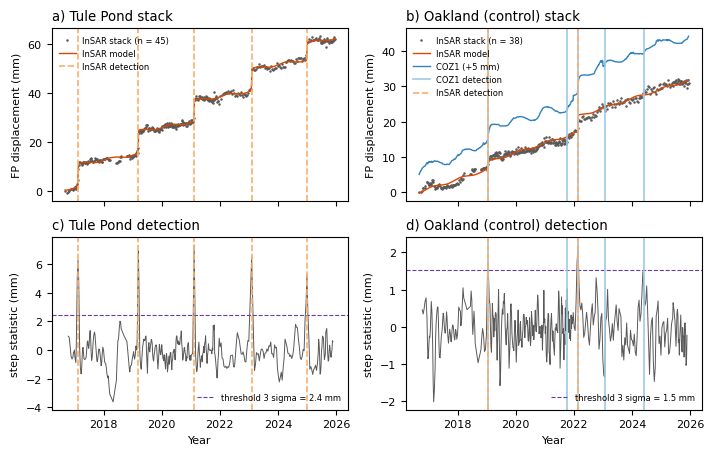

In [7]:
plt.rcParams.update({"font.size": 8})
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.6), sharex=True)
for j, (title, key, col, centre, half_span, cmcode) in enumerate(SEGS):
    q = qc[key]
    ax = axes[0, j]
    ax.plot(q["tt"], q["y"] - q["y"][0], ".", ms=1.6, color="0.35", label=f"InSAR stack (n = {q['n']})")
    G = design(q["tt"], [f["onset_yr"] for f in q["fits"]]); m, *_ = np.linalg.lstsq(G, q["y"], rcond=None)
    ax.plot(q["tt"], G @ m - q["y"][0], "-", lw=1.0, color="#D94801", label="InSAR model")
    if q["cm_series"] is not None:
        tc, cc = q["cm_series"]; ax.plot(tc, cc - cc[0] + 5.0, "-", lw=1.0, color="#3182BD", label=f"{cmcode} (+5 mm)")
    for k_, (e, _) in enumerate(q["cm_ev"]):
        ax.axvline(e, color="#9ECAE1", lw=1.2, label=f"{cmcode} detection" if k_ == 0 else None)
    for k_, (onset, _) in enumerate(q["events"]):
        ax.axvline(onset, color="#FDAE6B", lw=1.2, ls="--", label="InSAR detection" if k_ == 0 else None)
    ax.set_ylabel("FP displacement (mm)"); ax.set_title(f"{'ab'[j]}) {title} stack", loc="left")
    ax.legend(fontsize=6, loc="upper left", frameon=False)
    ax = axes[1, j]
    ax.axhline(k_sigma * q["sig"], color="#6A3D9A", lw=0.8, ls="--", label=f"threshold {k_sigma:g} sigma = {k_sigma * q['sig']:.1f} mm")
    ax.plot(q["mid"], q["val"], "-", lw=0.7, color="0.35")
    for e, _ in q["cm_ev"]:
        ax.axvline(e, color="#9ECAE1", lw=1.2)
    for onset, _ in q["events"]:
        ax.axvline(onset, color="#FDAE6B", lw=1.2, ls="--")
    ax.set_ylabel("step statistic (mm)"); ax.set_xlabel("Year"); ax.set_title(f"{'cd'[j]}) {title} detection", loc="left")
    ax.legend(fontsize=6, loc="lower right", frameon=False)
fig.tight_layout()
f_det = os.path.join(fig_dir, f"figS_event_detection_{params}_k{k_sigma:g}_win{win_n}.png")
fig.savefig(f_det, dpi=300); fig.savefig(f_det.replace(".png", ".pdf")); print("Saved figure to:", f_det)
plt.show()

## Along strike: the joint model at every crossing

The same design (linear + annual + a step at each onset, held fixed) fitted
crossing by crossing. Away from its section an event's amplitude fits to
noise about zero, which is how the along-strike extent is read. The
event-driven fraction is the section's summed event slip over the total slip
in the window; it is a regression ratio and is not confined to 0 to 100%.

In [8]:
onsets_all = ev["onset_yr"].to_numpy(float); seg_of = ev["segment"].to_numpy()
G_full = design(t, onsets_all)
rate = np.full(len(lat), np.nan); amps = np.full((len(onsets_all), len(lat)), np.nan)
for i in range(len(lat)):
    yy = F[i]; ok = np.isfinite(yy)
    if ok.sum() < min_epoch_frac * len(t):
        continue
    m, *_ = np.linalg.lstsq(G_full[ok], yy[ok], rcond=None)
    rate[i] = m[1]; amps[:, i] = m[4:]


def gaussian_smooth_km(x, lats, sigma_km):
    """NaN-aware, gap-preserving Gaussian smoothing along the fault."""
    from scipy.ndimage import gaussian_filter1d
    spacing = float(np.median(np.abs(np.diff(lats)))) * 111.19
    sig = max(sigma_km / spacing, 0.5)
    fin = np.isfinite(x).astype(float); filled = np.where(fin > 0, x, 0.0)
    den = gaussian_filter1d(fin, sig, mode="nearest")
    out = np.divide(gaussian_filter1d(filled, sig, mode="nearest"), den, out=np.full_like(filled, np.nan), where=den > 0.15)
    out[~np.isfinite(x)] = np.nan
    return out


def interp_nan(x, y):
    """Bridge NaN gaps inside the data range by linear interpolation (x must be sorted)."""
    y = np.asarray(y, float).copy(); m = np.isfinite(y)
    if m.sum() >= 2:
        inner = (x >= x[m][0]) & (x <= x[m][-1]); fill = inner & ~m
        y[fill] = np.interp(x[fill], x[m], y[m])
    return y


cols = {"lat": lat, "km": km, "inter_event_rate": rate, "inter_event_rate_smooth": gaussian_smooth_km(rate, lat, smooth_km)}
frac_stats = {}
for title, key, col, centre, half_span, cmcode in SEGS:
    sel = seg_of == key
    s = amps[sel].sum(axis=0); total = rate * span + s
    frac = 100 * s / np.where(np.abs(total) > total_floor_mm, total, np.nan)
    cols[f"event_sum_{col}"] = s; cols[f"event_frac_{col}"] = frac
    cols[f"event_frac_{col}_smooth"] = gaussian_smooth_km(frac, lat, smooth_km)
    for j in np.flatnonzero(sel):
        cols[f"amp_{onsets_all[j]:.3f}"] = amps[j]
    d = 2.0 / 111.19
    inseg = (lat >= segments[key]["lat"] - d) & (lat <= segments[key]["lat"] + d)
    v = frac[inseg & np.isfinite(frac)]
    frac_stats[key] = dict(n=int(inseg.sum()), sum_median=float(np.nanmedian(s[inseg])), median=float(np.median(v)),
                           p5=float(np.percentile(v, 5)), p95=float(np.percentile(v, 95)))
    print(f"{title}: {inseg.sum()} crossings within 2 km; summed event slip median {np.nanmedian(s[inseg]):.1f} mm; "
          f"fraction median {np.median(v):.0f}%, 5-95% {np.percentile(v, 5):.0f} to {np.percentile(v, 95):.0f}%")
fr = pd.DataFrame(cols)
fr.to_csv(os.path.join(out_dir, "event_fraction_by_crossing.csv"), index=False)

Tule Pond: 46 crossings within 2 km; summed event slip median 47.9 mm; fraction median 77%, 5-95% 31 to 97%
Oakland (control): 42 crossings within 2 km; summed event slip median 6.7 mm; fraction median 21%, 5-95% 9 to 37%


## The window around the section, and the slip above the inter-event rate

Per crossing, a linear + annual model is fitted to the INTER-event epochs only
(the event windows enter as ramp columns so they do not pull the trend) and
subtracted from every epoch: what is left is the cumulative slip above the
inter-event rate, the hovmoller of Fig 1. The 20 km window for everything
along strike is re-centred on the peak of that cumulative slip at the end of
the record, so it follows the data rather than the seed centre.

In [9]:
def event_detrend(Fm, tt, windows):
    G = np.column_stack([np.ones_like(tt), tt, np.sin(2 * np.pi * tt), np.cos(2 * np.pi * tt)]
                        + [np.clip((tt - s_) / (e_ - s_), 0, 1) for s_, e_ in windows])
    inter = np.ones_like(tt, dtype=bool)
    for s_, e_ in windows:
        inter &= ~((tt >= s_) & (tt <= e_))
    res = np.full_like(Fm, np.nan); rates = []
    for i in range(Fm.shape[0]):
        yy = Fm[i]; ok = np.isfinite(yy) & inter
        if ok.sum() < 10:
            continue
        c = np.linalg.lstsq(G[ok], yy[ok], rcond=None)[0]
        res[i] = yy - G[:, :4] @ c[:4]; rates.append(c[1])
    return res, float(np.nanmedian(rates))


title, key, col, centre, half_span, cmcode = SEGS[0]
windows = list(zip(tp["onset_lo"], tp["onset_hi"]))
res, bg_rate = event_detrend(F, t, windows)
res = np.column_stack([gaussian_smooth_km(res[:, j], lat, smooth_km) for j in range(res.shape[1])])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    final = np.nanmean(res[:, -5:], axis=1)
w0 = (km >= centre - half_span) & (km <= centre + half_span)
c_new = float(km[w0][np.nanargmax(final[w0])])
centre = min(max(c_new, km.min() + half_span), km.max() - half_span)
w_lo, w_hi = centre - half_span, centre + half_span
print(f"window re-centred on the cumulative-slip peak at {c_new:.1f} km: {w_lo:.1f} to {w_hi:.1f} km; "
      f"median per-crossing inter-event rate in the window {bg_rate:.2f} mm/yr")

window re-centred on the cumulative-slip peak at 58.8 km: 48.3 to 68.3 km; median per-crossing inter-event rate in the window 4.56 mm/yr


## Section lengths (Dani's sketch, 2026-09-21)

Two lengths on the cumulative event slip profile of Tule Pond:

1. **Length of fault hosting the events**: the contiguous span around the peak
   over which the cumulative event slip (sum of the five steps, 0.4 km
   smoothed, short gaps bridged) stays above the flank noise. The threshold is
   3 robust sigma of the same profile on the flanks (52 to 56 and 64 to 68
   km), so it comes from the data. The spans above 10% and 20% of the peak
   are printed beside it as a sensitivity check.
2. **Width of the peak slip zone**: the contiguous run where the smoothed
   event-driven fraction is at least 75% (and, alternatively, 90%) of its
   peak. The 75% band is what the figures draw.

In [10]:
def contiguous_span(k, v, thresh):
    """Span (lo, hi, n) of the contiguous run around the peak where v >= thresh; k sorted."""
    j = int(np.nanargmax(v)); above = np.isfinite(v) & (v >= thresh)
    lo = hi = j
    while lo > 0 and above[lo - 1]: lo -= 1
    while hi < len(v) - 1 and above[hi + 1]: hi += 1
    return float(k[lo]), float(k[hi]), int(hi - lo + 1)


win = (ks >= w_lo) & (ks <= w_hi)
cum = interp_nan(ks, gaussian_smooth_km(fr[f"event_sum_{col}"].values, lat, smooth_km)[o])
cum_w = np.where(win, cum, np.nan)
flank = np.zeros(len(ks), bool)
for a_, b_ in flank_km:
    flank |= (ks >= a_) & (ks <= b_)
flank_sigma = utils.robust_sigma(cum[flank]); flank_median = np.nanmedian(cum[flank])
thr = flank_median + 3 * flank_sigma
peak_cum = float(np.nanmax(cum_w))
len_lo, len_hi, len_n = contiguous_span(ks, cum_w, thr)
print(f"cumulative event slip: peak {peak_cum:.1f} mm at {ks[np.nanargmax(cum_w)]:.1f} km; "
      f"flanks median {flank_median:.1f} mm, robust sigma {flank_sigma:.2f} mm -> threshold {thr:.1f} mm")
print(f"  length of fault hosting the events (above threshold): {len_lo:.1f} to {len_hi:.1f} km = {len_hi - len_lo:.1f} km ({len_n} crossings)")
lengths = {"threshold": (len_lo, len_hi)}
for pct in (10, 20):
    a_, b_, n_ = contiguous_span(ks, cum_w, pct / 100 * peak_cum)
    lengths[f"{pct}pct"] = (a_, b_)
    print(f"  sensitivity, above {pct}% of peak: {a_:.1f} to {b_:.1f} km = {b_ - a_:.1f} km")

frac_s = interp_nan(ks, fr[f"event_frac_{col}_smooth"].values[o])
secular_s = interp_nan(ks, fr["inter_event_rate_smooth"].values[o])
frac_w = np.where(win, frac_s, np.nan)
peak_frac = float(np.nanmax(frac_w))
bands = {}
for bf in band_fracs:
    b_lo, b_hi, b_n = contiguous_span(ks, frac_w, bf * peak_frac)
    bands[bf] = (b_lo, b_hi, b_n)
    print(f"  peak slip zone at {100 * bf:.0f}% of the fraction peak ({peak_frac:.0f}%): {b_lo:.1f} to {b_hi:.1f} km = {b_hi - b_lo:.1f} km, {b_n} crossings")

# the control: COZ1's 75% band on its own fraction
frac_c = interp_nan(ks, fr["event_frac_coz1_smooth"].values[o])
win_c = (ks >= SEGS[1][3] - SEGS[1][4]) & (ks <= SEGS[1][3] + SEGS[1][4])
c_lo, c_hi, c_n = contiguous_span(ks, np.where(win_c, frac_c, np.nan), 0.75 * np.nanmax(np.where(win_c, frac_c, np.nan)))

# the measured extents, for the map brackets (notebook 05) and the text
b_lo, b_hi, b_n = bands[band_main]
pd.DataFrame([dict(name="tulepond_creep_length", km_lo=len_lo, km_hi=len_hi, lat_lo=lat_of_km(len_hi), lat_hi=lat_of_km(len_lo), n=len_n),
              dict(name="tulepond_band75", km_lo=bands[0.75][0], km_hi=bands[0.75][1], lat_lo=lat_of_km(bands[0.75][1]), lat_hi=lat_of_km(bands[0.75][0]), n=bands[0.75][2]),
              dict(name="tulepond_band90", km_lo=bands[0.90][0], km_hi=bands[0.90][1], lat_lo=lat_of_km(bands[0.90][1]), lat_hi=lat_of_km(bands[0.90][0]), n=bands[0.90][2]),
              dict(name="oakland_band75", km_lo=c_lo, km_hi=c_hi, lat_lo=lat_of_km(c_hi), lat_hi=lat_of_km(c_lo), n=c_n)]
             ).to_csv(os.path.join(out_dir, "section_lengths.csv"), index=False)
print("Saved section_lengths.csv")

cumulative event slip: peak 52.1 mm at 58.8 km; flanks median 0.2 mm, robust sigma 1.97 mm -> threshold 6.1 mm
  length of fault hosting the events (above threshold): 56.3 to 62.3 km = 6.0 km (60 crossings)
  sensitivity, above 10% of peak: 56.3 to 62.4 km = 6.1 km
  sensitivity, above 20% of peak: 56.7 to 62.0 km = 5.3 km
  peak slip zone at 75% of the fraction peak (88%): 57.8 to 60.5 km = 2.7 km, 28 crossings
  peak slip zone at 90% of the fraction peak (88%): 58.2 to 59.8 km = 1.6 km, 17 crossings
Saved section_lengths.csv


## The band stack: the five events

Mean of the crossings inside the peak slip zone, then the joint model with
the catalogue onsets and block-bootstrap CIs on the steps. Done for both
band definitions; the figures draw the 75% band. The draft's numbers (same
code, same 0.7 stream, July 2026) are printed for comparison.

In [11]:
def band_stack(lo_km, hi_km, onsets):
    sel = (km >= lo_km) & (km <= hi_km)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        mean = np.nanmean(F[sel], axis=0); std = np.nanstd(F[sel], axis=0)
    fin = np.isfinite(mean); mean = mean - mean[fin][0]
    m, rss = fit_joint(t[fin], mean[fin], onsets)
    lo_, hi_ = bootstrap_amplitudes(t[fin], mean[fin], onsets)
    return dict(n=int(sel.sum()), mean=mean, std=std, m=m, steps=m[4:], lo=lo_, hi=hi_,
                secular=float(m[1]), annual=float(np.hypot(m[2], m[3])), rms=float(np.sqrt(rss / fin.sum())))


band_res = {}
for bf, (lo_km, hi_km, n_) in bands.items():
    bres = band_stack(lo_km, hi_km, onsets_tp)
    band_res[bf] = bres
    pd.DataFrame({"t": t, "stack_mm": bres["mean"], "std_mm": bres["std"]}).to_csv(os.path.join(out_dir, f"band_stack_{int(bf * 100)}pct.csv"), index=False)
    print(f"band {100 * bf:.0f}%: {lo_km:.1f} to {hi_km:.1f} km, n = {bres['n']} crossings; secular {bres['secular']:.2f} mm/yr, "
          f"annual {bres['annual']:.2f} mm, rms {bres['rms']:.2f} mm")
    for on, a_, l_, h_ in zip(onsets_tp, bres["steps"], bres["lo"], bres["hi"]):
        print(f"    {on:.3f}: {a_:5.2f} mm  [{l_:.2f}, {h_:.2f}]")
    print(f"    sum {np.sum(bres['steps']):.1f} mm, mean {np.mean(bres['steps']):.1f} mm, range {np.min(bres['steps']):.1f} to {np.max(bres['steps']):.1f} mm")
    print("    95% CI overlap with the others (y/n per event): " + ", ".join(
        f"{on:.0f}:" + "".join("y" if (l1 <= h2 and l2 <= h1) else "n" for (l2, h2) in zip(bres["lo"], bres["hi"]))
        for on, (l1, h1) in zip(onsets_tp, zip(bres["lo"], bres["hi"]))))
    print("")
print("draft (July 2026, 75% band 57.7 to 60.1 km, 25 crossings): 10.84, 10.46, 10.70, 11.16, 7.67 mm, sum 50.8, secular 1.08 mm/yr")
coz1_band = band_stack(c_lo, c_hi, ev[ev.segment == "COZ1"]["onset_yr"].to_numpy(float))
print(f"control, Oakland 75% band {c_lo:.1f} to {c_hi:.1f} km (n = {coz1_band['n']}): steps " +
      ", ".join(f"{a_:.2f}" for a_ in coz1_band["steps"]) + f" mm, secular {coz1_band['secular']:.2f} mm/yr")

band 75%: 57.8 to 60.5 km, n = 28 crossings; secular 1.24 mm/yr, annual 0.63 mm, rms 0.94 mm
    2017.099: 10.91 mm  [9.71, 11.98]
    2019.186: 10.47 mm  [9.36, 11.45]
    2021.107: 10.47 mm  [9.47, 11.38]
    2023.080: 10.93 mm  [9.90, 11.85]
    2024.984:  7.84 mm  [6.99, 8.72]
    sum 50.6 mm, mean 10.1 mm, range 7.8 to 10.9 mm
    95% CI overlap with the others (y/n per event): 2017:yyyyn, 2019:yyyyn, 2021:yyyyn, 2023:yyyyn, 2025:nnnny

band 90%: 58.2 to 59.8 km, n = 17 crossings; secular 0.94 mm/yr, annual 0.80 mm, rms 1.20 mm
    2017.099: 10.62 mm  [8.76, 12.12]
    2019.186: 10.45 mm  [8.86, 11.94]
    2021.107: 11.17 mm  [9.68, 12.57]
    2023.080: 11.82 mm  [10.29, 13.29]
    2024.984:  7.62 mm  [6.29, 9.04]
    sum 51.7 mm, mean 10.3 mm, range 7.6 to 11.8 mm
    95% CI overlap with the others (y/n per event): 2017:yyyyy, 2019:yyyyy, 2021:yyyyn, 2023:yyyyn, 2025:yynny

draft (July 2026, 75% band 57.7 to 60.1 km, 25 crossings): 10.84, 10.46, 10.70, 11.16, 7.67 mm, sum 50.8, s

## The slip budget, the alignment arrays and the creepmeters

Per crossing: inter-event rate, the summed event steps over the record
length, and their sum, smoothed 0.5 km. The alignment arrays enter twice:
refit over the InSAR window from their survey files (black in the figures;
needs 4 surveys spanning 5 yr), and the archive's whole-record rate (grey).
Creepmeter rates are over the InSAR window.

In [12]:
amp_cols = [c for c in fr.columns if c.startswith("amp_")]
bud = fr[["lat", "km"]].copy()
bud["secular"] = fr["inter_event_rate"]
bud["event_sum"] = fr[amp_cols].sum(axis=1, min_count=1)
bud["event_rate"] = bud["event_sum"] / span
bud["total"] = bud["secular"] + bud["event_rate"]
bud = bud.sort_values("km").reset_index(drop=True)
for k_ in ("secular", "event_rate", "total"):
    bud[f"{k_}_smooth"] = gaussian_smooth_km(bud[k_].values, bud["lat"].values, rate_smooth_km)
bud.to_csv(os.path.join(out_dir, "slip_budget_by_crossing.csv"), index=False)

# alignment arrays: window refit (black) and whole-record rate (grey)
aa_sum = utils.load_aa_summary(common_paths["aa_summary"])
aa_sum = utils.project_to_fault(aa_sum, prof, lon_col="long_deg", lat_col="lat_deg")
aa_rows = []
for _, r_ in aa_sum.iterrows():
    if abs(r_.dist_fault_km) > 2.0:
        continue
    try:
        aa = utils.load_aa(common_paths["aa_dir"], r_.site_code)
    except (FileNotFoundError, ValueError) as e:
        print(f"  AA {r_.site_code}: skipped ({e})"); continue
    w = aa[(aa.year >= t0) & (aa.year <= t1)]
    sp = w.year.max() - w.year.min() if len(w) else 0.0
    rate_win = float(np.polyfit(w.year.values, w.cum_mm.values, 1)[0]) if (len(w) >= aa_min_surveys and sp >= aa_min_span_yr) else np.nan
    aa_rows.append(dict(code=r_.site_code, name=r_.site_name, lat=r_.lat_deg, lon=r_.long_deg, km=float(to_km([r_.lat_deg])[0]),
                        rate_window=rate_win, n_window=len(w), span_window=sp,
                        rate_longterm=float(r_["rate_lnrr"]), first_yr=float(r_["first_yr"]), last_yr=float(r_["last_yr"])))
aa_df = pd.DataFrame(aa_rows).sort_values("km")
aa_df.to_csv(os.path.join(out_dir, "aa_rates.csv"), index=False)
print(f"{len(aa_df)} Hayward arrays within 2 km of the trace; {aa_df.rate_window.notna().sum()} refit over the InSAR window")
cm_rates = {}
for code, la, lo, name in creepmeters:
    tc, cc = daily_creepmeter(code)
    cm_rates[code] = (float(to_km([la])[0]), utils.linear_rate(tc, cc)[0])


def budget_block(name, lo, hi):
    w = (bud.km >= lo) & (bud.km <= hi)
    la = aa_df[(aa_df.km >= lo - 1.0) & (aa_df.km <= hi + 1.0)]
    out = dict(name=name, lo=lo, hi=hi, n=int(w.sum()),
               secular=float(bud.loc[w, "secular"].mean()), event_rate=float(bud.loc[w, "event_rate"].mean()),
               total=float(bud.loc[w, "total"].mean()),
               frac_pct=100 * bud.loc[w, "event_rate"].mean() / max(bud.loc[w, "total"].mean(), 1e-9),
               aa_window_mean=float(la.rate_window.mean()), aa_window_n=int(la.rate_window.notna().sum()),
               aa_longterm_mean=float(la.rate_longterm.mean()), aa_n=len(la))
    print(f"[{name}] {lo:.1f} to {hi:.1f} km, n = {out['n']}: secular {out['secular']:.2f}, event-driven {out['event_rate']:.2f}, "
          f"total {out['total']:.2f} mm/yr ({out['frac_pct']:.0f}% event-driven); arrays: window {out['aa_window_mean']:.2f} (n {out['aa_window_n']}), "
          f"long-term {out['aa_longterm_mean']:.2f} (n {out['aa_n']}) mm/yr")
    return out


budget = {}
for bf, (lo_km, hi_km, n_) in bands.items():
    budget[f"band{int(bf * 100)}"] = budget_block(f"Tule Pond {100 * bf:.0f}% band", lo_km, hi_km)
budget["length"] = budget_block("Tule Pond, length hosting events", len_lo, len_hi)
budget["flanks"] = budget_block("Tule Pond flanks (band +/- 5 km)", b_lo - 5.0, b_hi + 5.0)
budget["coz1"] = budget_block("Oakland control 75% band", c_lo, c_hi)

33 Hayward arrays within 2 km of the trace; 30 refit over the InSAR window


[Tule Pond 75% band] 57.8 to 60.5 km, n = 28: secular 1.17, event-driven 5.53, total 6.70 mm/yr (83% event-driven); arrays: window 6.92 (n 2), long-term 5.86 (n 2) mm/yr
[Tule Pond 90% band] 58.2 to 59.8 km, n = 17: secular 0.83, event-driven 5.67, total 6.50 mm/yr (87% event-driven); arrays: window 6.88 (n 1), long-term 6.08 (n 1) mm/yr
[Tule Pond, length hosting events] 56.3 to 62.3 km, n = 60: secular 2.80, event-driven 3.70, total 6.50 mm/yr (57% event-driven); arrays: window 6.96 (n 4), long-term 6.32 (n 4) mm/yr
[Tule Pond flanks (band +/- 5 km)] 53.2 to 64.8 km, n = 107: secular 4.07, event-driven 2.33, total 6.40 mm/yr (36% event-driven); arrays: window 6.92 (n 8), long-term 6.39 (n 8) mm/yr
[Oakland control 75% band] 30.5 to 34.6 km, n = 35: secular 2.84, event-driven 0.51, total 3.35 mm/yr (15% event-driven); arrays: window 5.27 (n 2), long-term 3.51 (n 2) mm/yr


## Recurrence intervals, and seismicity near the section

Seismicity is Bo Xie's GrowClust relocated catalogue (relocated plus
unrelocated NCSS events); repeaters are Taira GEN3 plus Waldhauser and
Schaff; both within 2 km of the trace and inside the InSAR window.

In [13]:
intervals = np.diff(onsets_tp)
print("intervals between the five onsets (yr): " + ", ".join(f"{x:.2f}" for x in intervals))
print(f"mean {intervals.mean():.2f} yr, sd {intervals.std(ddof=1) * 365.25:.0f} d, CoV {intervals.std(ddof=1) / intervals.mean():.2f}")

seis = utils.load_growclust_catalog(common_paths["growclust_cat"], bbox=common_paths["aoi_bbox"])
seis = utils.project_to_fault(seis, prof)
seis = seis[(seis.dist_fault_km.abs() <= seis_max_dist_km) & (seis.YYYY >= t0) & (seis.YYYY <= t1)].copy()
seis["km"] = to_km(seis["ft_lat"].values)
cre = pd.concat([utils.load_cre_taira(common_paths["CRE_Taira"]), utils.load_cre_waldhauser(common_paths["CRE_Wald"])], ignore_index=True)
cre = cre.dropna(subset=["YYYY", "Lon", "Lat", "Mag"])
w_, s_, e_, n_ = common_paths["aoi_bbox"]
cre = cre[(cre.Lon >= w_) & (cre.Lon <= e_) & (cre.Lat >= s_) & (cre.Lat <= n_)]
cre = utils.project_to_fault(cre, prof)
cre = cre[(cre.dist_fault_km.abs() <= seis_max_dist_km) & (cre.YYYY >= t0) & (cre.YYYY <= t1)].copy()
cre["km"] = to_km(cre["ft_lat"].values)
qh = seis[(seis.km >= w_lo) & (seis.km <= w_hi)]; ch = cre[(cre.km >= w_lo) & (cre.km <= w_hi)]
n_seis_win, n_cre_win = len(qh), len(ch)
n_cre_band = int(((cre.km >= b_lo) & (cre.km <= b_hi)).sum())
print(f"within {seis_max_dist_km:g} km of the trace, {t0:.1f} to {t1:.1f}: {len(seis)} earthquakes ({(seis.source == 'growclust').sum()} relocated) "
      f"and {len(cre)} repeaters on the whole fault; in the Tule Pond window ({w_lo:.0f} to {w_hi:.0f} km): {n_seis_win} earthquakes, "
      f"{n_cre_win} repeaters; in the 75% band: {n_cre_band} repeaters")

intervals between the five onsets (yr): 2.09, 1.92, 1.97, 1.90
mean 1.97 yr, sd 30 d, CoV 0.04
within 2 km of the trace, 2016.7 to 2026.0: 1927 earthquakes (1660 relocated) and 143 repeaters on the whole fault; in the Tule Pond window (48 to 68 km): 234 earthquakes, 18 repeaters; in the 75% band: 0 repeaters


## Figure 1 (all pygmt, one font)

a) Map: fault-parallel velocity (notebook 02) on a page rotated to the mean
strike; creepmeter ticks; the bracket is the measured length of fault
hosting the events. b) Tule Pond, slip above the inter-event rate at every
crossing in the window, with the relocated seismicity (circles, depth colour,
size by magnitude) and the repeaters (green squares); dashed lines at the
75% band. c) InSAR stack: the plain mean of the fault-parallel series of the
band crossings, zeroed at the first epoch, nothing subtracted; the joint
model (teal between events, orange across the steps) is drawn over it.
d) Cumulative slip per event along strike. e) Creep rates: inter-event
(teal), event-driven (orange), their sum (black); creepmeters over the
InSAR window (gold), alignment arrays refit over the same window (black) and
their whole-record rates (grey).

  CPP1: 39 m from the nearest trace vertex
  CTM1: 14 m from the nearest trace vertex
  COZ1: 56 m from the nearest trace vertex
  CHP1: 44 m from the nearest trace vertex
  CFW1: 26 m from the nearest trace vertex
map display reference: west block +1.28, east block +5.79 mm/yr; mid-point removed
map panel 3.53 x 11.40 cm at true scale


Saved Fig 1 to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/fig1_tulepond_ap30-150m_coh0.7_mp5_sw200m_band90.png


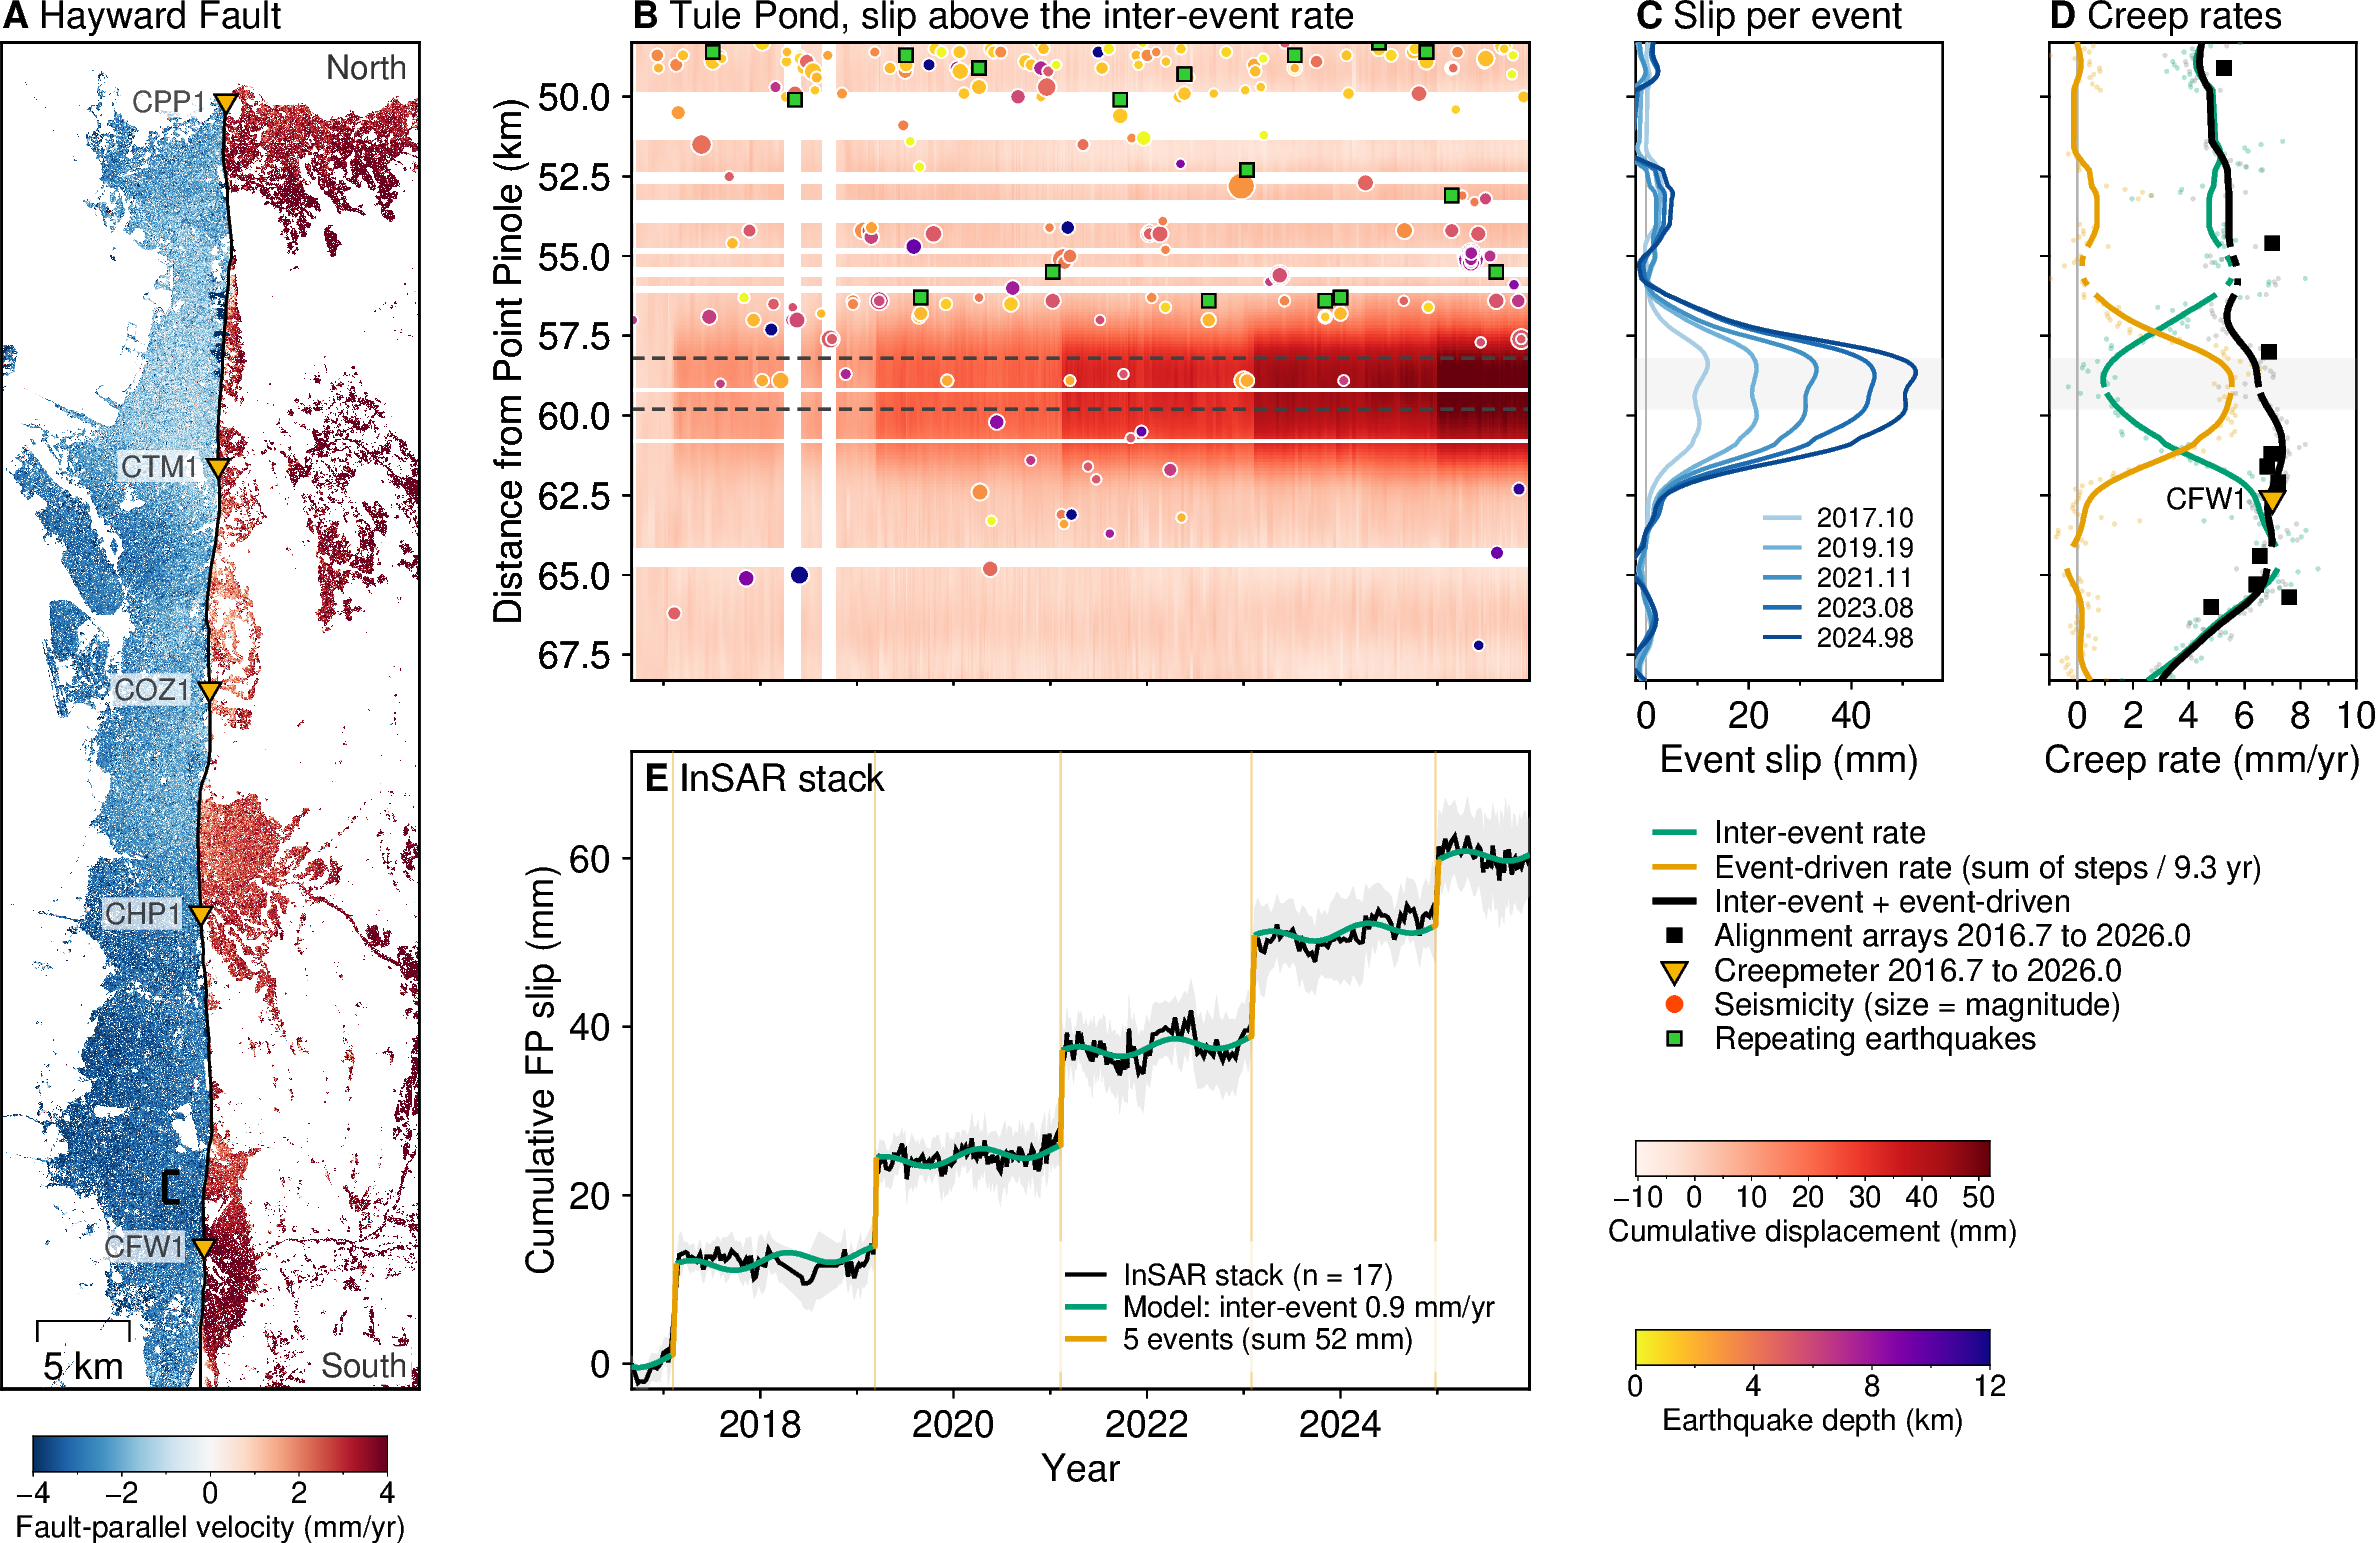

In [14]:
import h5py


# --- a) the map on the rotated frame (as notebook 02) ---
with h5py.File(map_file, "r") as h:
    fp_map = h["fp_velocity"][:].astype(float)
    attrs = {k: (v.decode() if isinstance(v, bytes) else str(v)) for k, v in h.attrs.items()}
fp_map[fp_map == 0] = np.nan
utm = pyproj.Transformer.from_crs(4326, int(attrs["EPSG"]), always_xy=True)
fe, fn = utm.transform(prof["ft_lon"].values, prof["ft_lat"].values)
th = np.deg2rad(strike_map)
ae, an = np.sin(th), np.cos(th); pe, pn = -np.cos(th), np.sin(th)       # along-strike (SE) and cross-fault (NE) unit vectors
u_tr, v_tr = fe * ae + fn * an, fe * pe + fn * pn
u0, v0 = float(u_tr[int(np.argmax(prof["ft_lat"].values))]), float(np.median(v_tr))


def to_uv(lon, lat_):
    e, n = utm.transform(np.asarray(lon, float), np.asarray(lat_, float))
    return ((e * ae + n * an) - u0) / 1e3, ((e * pe + n * pn) - v0) / 1e3


tu, tv = to_uv(prof["ft_lon"].values, prof["ft_lat"].values)
u_south = float(tu.max())
from_utm = pyproj.Transformer.from_crs(int(attrs["EPSG"]), 4326, always_xy=True)


def uv_to_lonlat(u, v):
    """Inverse of to_uv: strike-frame km -> lon/lat (for the few things defined in the frame: corners, the bracket)."""
    u, v = np.asarray(u, float) * 1e3 + u0, np.asarray(v, float) * 1e3 + v0
    return from_utm.transform(u * ae + v * pe, u * an + v * pn)


# The map is drawn with GMT's oblique Mercator: x axis along strike_map - 90 (north-east, across the
# fault), so the fault runs up the page with north at the top. The region is the rectangle in the
# strike frame: u from -3 km (north of Point Pinole) to map_u_max, v +/- map_half_km. Every point is
# then plotted in lon/lat, no hand rotation.
lon_ll, lat_ll = uv_to_lonlat(map_u_max, -map_half_km)          # lower-left = south end, west side
lon_ur, lat_ur = uv_to_lonlat(-3.0, map_half_km)                 # upper-right = north end, east side
lon_c, lat_c = uv_to_lonlat(0.5 * (map_u_max - 3.0), 0.0)
corners = np.array([uv_to_lonlat(u_, v_) for u_, v_ in ((map_u_max, -map_half_km), (map_u_max, map_half_km), (-3.0, map_half_km), (-3.0, -map_half_km))])


def gmt_map_size(region, projection):
    """Width and height (cm) GMT gives a region/projection pair (mapproject -W), so panels can be aligned to it."""
    with pygmt.clib.Session() as lib:
        f_ = os.path.join(out_dir, "cpt", "dims.txt")
        lib.call_module("mapproject", f"-R{region} -J{projection} -W ->{f_}")
    return tuple(float(x) for x in open(f_).read().split())



# the FP velocity on a regular lon/lat grid (nearest UTM pixel), referenced in the strike frame
lat_g = np.arange(corners[:, 1].min() - 0.01, corners[:, 1].max() + 0.01, 0.00028)
lon_g = np.arange(corners[:, 0].min() - 0.01, corners[:, 0].max() + 0.01, 0.00035)
LON, LAT = np.meshgrid(lon_g, lat_g)
E, N = utm.transform(LON, LAT)
x0, dx = float(attrs["X_FIRST"]), float(attrs["X_STEP"]); y0, dy = float(attrs["Y_FIRST"]), float(attrs["Y_STEP"])
ci = np.round((E - x0) / dx).astype(int); ri = np.round((N - y0) / dy).astype(int)
okm = (ci >= 0) & (ci < fp_map.shape[1]) & (ri >= 0) & (ri < fp_map.shape[0])
z = np.full(LON.shape, np.nan); z[okm] = fp_map[ri[okm], ci[okm]]
U_g, V_g = ((E * ae + N * an) - u0) / 1e3, ((E * pe + N * pn) - v0) / 1e3     # strike-frame coordinates of the grid nodes
# creepmeter positions: the instruments sit on the trace to within a few tens of metres (printed)
u_cm = {}
for code, la, lo, name in creepmeters:
    ui, vi = to_uv(lo, la); j = int(np.argmin(np.hypot(tu - ui, tv - vi)))
    u_cm[code] = float(tu[j])
    print(f"  {code}: {1e3 * np.hypot(tu[j] - ui, tv[j] - vi):.0f} m from the nearest trace vertex")
lo_u, hi_u = sorted([u_cm["CTM1"], u_cm["COZ1"]])
# display reference: the mid-point of the two blocks' medians in the CTM1-COZ1 patch, so the
# fault sits at zero and the colour scale swings equally blue (west) and red (east)
in_u = (U_g >= lo_u) & (U_g <= hi_u)
z_west = np.nanmedian(z[in_u & (V_g < 0) & (V_g >= -ref_patch_km)])
z_east = np.nanmedian(z[in_u & (V_g > 0) & (V_g <= ref_patch_km)])
z = z - 0.5 * (z_west + z_east)
vel_lim = 4.0           # colour range +/- this (mm/yr); the block medians are ~ +/- 2.5 to 3
print(f"map display reference: west block {z_west:+.2f}, east block {z_east:+.2f} mm/yr; mid-point removed")
grid_ll = xr.DataArray(z, coords={"lat": lat_g, "lon": lon_g}, dims=("lat", "lon"))

# --- b) the hovmoller on a regular 6-day time grid (GMT grids must be regular) ---
show = (km >= w_lo) & (km <= w_hi); osh = np.argsort(km[show])
grid = np.arange(w_lo, w_hi + 0.05, 0.1)
gres = np.full((grid.size, res.shape[1]), np.nan)
gi = np.round((km[show][osh] - grid[0]) / 0.1).astype(int); okg = (gi >= 0) & (gi < grid.size)
gres[gi[okg]] = res[show][osh][okg]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    vmax = max(float(np.nanpercentile(res[show], 99.5)), 1.0)
vmin = -neg_floor_frac * vmax
t_reg = np.arange(t0, t1 + 1e-9, 6.0 / 365.25)
near = np.abs(t_reg[:, None] - t[None, :]).argmin(axis=1)
hov = gres[:, near]; hov[:, np.abs(t_reg - t[near]) > 9.0 / 365.25] = np.nan
grid_hov = xr.DataArray(hov, coords={"y": grid, "x": t_reg}, dims=("y", "x"))

# --- d) per-event cumulative slip profiles ---
rows_w = np.where(show)[0][osh]; kw, latw = km[show][osh], lat[show][osh]
Gf = design(t, onsets_tp); A = np.full((rows_w.size, onsets_tp.size), np.nan)
for ii, ri_ in enumerate(rows_w):
    fin_r = np.isfinite(F[ri_])
    if fin_r.sum() > Gf.shape[1] + 10:
        sol, *_ = np.linalg.lstsq(Gf[fin_r], F[ri_][fin_r], rcond=None); A[ii] = sol[4:]
cum_prof = np.zeros((onsets_tp.size, rows_w.size)); run = np.zeros(rows_w.size)
for i in range(onsets_tp.size):
    run = run + np.nan_to_num(interp_nan(kw, gaussian_smooth_km(A[:, i], latw, 0.3)))
    cum_prof[i] = run
resb = band_res[band_main]
full = design(t, onsets_tp) @ resb["m"]
in_ev = np.zeros(t.size, bool)
for on in onsets_tp:
    j = int(np.searchsorted(t, on))
    if 0 < j < t.size: in_ev[j] = True
grow = in_ev.copy(); grow[1:] |= in_ev[:-1]; grow[:-1] |= in_ev[1:]
np.savez(os.path.join(out_dir, "fig1_panels.npz"), t=t, grid=grid, gres=gres, vmin=vmin, vmax=vmax, kw=kw, cum_prof=cum_prof,
         onsets=onsets_tp, ks=ks, secular_smooth=secular_s, frac_smooth=frac_s, band_lo=b_lo, band_hi=b_hi,
         stack_mean=resb["mean"], stack_std=resb["std"], model=full, w_lo=w_lo, w_hi=w_hi, bg_rate=bg_rate,
         seis_t=qh.YYYY.values, seis_km=qh.km.values, seis_mag=qh.Mag.values, seis_depth=qh.Depth.values,
         cre_t=ch.YYYY.values, cre_km=ch.km.values)

# --- the figure: sizes in cm, double-column width, one font ---
teal, orange, cm_blue, gold = "#009E73", "#E69F00", "#0b3d91", "#F5B400"
Wh, Hh = 7.6, 5.4                  # hovmoller
Ws = Hh                            # stack: the same height as the hovmoller
gap_be = 0.6                       # between B and E (B has no x annotation, E has its label inside)
Wm, Hm = 3.4, Hh + gap_be + Ws     # map: as tall as B + gap + E, so the tops and bottoms line up
Wp, Wr, Hp = 2.6, 2.6, Hh          # profiles and rates panels: the same width
gap_map, gap_p, gap_r = 1.8, 0.9, 0.9
cb_w = 3.0                         # every colour bar the same size
cpt_dir = os.path.join(out_dir, "cpt"); os.makedirs(cpt_dir, exist_ok=True)
cpt_vel = utils.write_cpt(os.path.join(cpt_dir, "vel_vik.cpt"), "RdBu_r", -vel_lim, vel_lim)
cpt_hov = utils.write_cpt(os.path.join(cpt_dir, "hov_reds.cpt"), "Reds", vmin, vmax)
cpt_dep = utils.write_cpt(os.path.join(cpt_dir, "depth_plasma_r.cpt"), "plasma_r", 0, 12)

fig = pygmt.Figure()
pygmt.config(FONT="9p,Helvetica", FONT_ANNOT_PRIMARY="9p,Helvetica", FONT_LABEL="9p,Helvetica", FONT_TITLE="9p,Helvetica-Bold",
             MAP_FRAME_TYPE="plain", MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p")

# A) the map: GMT oblique Mercator, fault up the page, north at the top; everything in lon/lat
region_map = f"{lon_ll}/{lat_ll}/{lon_ur}/{lat_ur}+r"
w_, h_ = gmt_map_size(region_map, f"Oa{lon_c}/{lat_c}/{strike_map - 90}/{Wm}c")
Wm = Wm * Hm / h_                                                 # width that makes the map exactly Hm tall (true scale)
proj_map = f"Oa{lon_c}/{lat_c}/{strike_map - 90}/{Wm:.3f}c"
print(f"map panel {Wm:.2f} x {Hm:.2f} cm at true scale")
fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"])
fig.grdimage(grid=grid_ll, cmap=cpt_vel, nan_transparent=True)
fig.plot(x=prof["ft_lon"].values, y=prof["ft_lat"].values, pen="0.6p,black")
for code, la, lo, name in creepmeters:
    fig.plot(x=[lo], y=[la], style="i0.22c", fill=gold, pen="0.5p,black")                                    # the creepmeter symbol of D
    fig.text(x=lo, y=la, text=code, justify="RM", offset="-0.15c/0c", font="7p,Helvetica,black", fill="white", transparency=30)   # labels on the west (blue) side
# the bracket spans the stacked band (the peak-slip zone), the same span as the dashed lines in B
bx, by = uv_to_lonlat([b_lo, b_hi], [-2.2, -2.2]); fig.plot(x=bx, y=by, pen="1.2p,black")
for u_ in (b_lo, b_hi):
    bx, by = uv_to_lonlat([u_, u_], [-2.2, -1.4]); fig.plot(x=bx, y=by, pen="1.2p,black")
fig.text(position="TR", text="North", offset="-0.1c/-0.1c", font="8p,Helvetica,gray20", fill="white", clearance="0.05c")
fig.text(position="BR", text="South", offset="-0.1c/0.1c", font="8p,Helvetica,gray20", fill="white", clearance="0.05c")
fig.text(position="TL", text="@%Helvetica-Bold%A@%% Hayward Fault", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
fig.basemap(region=region_map, projection=proj_map, frame=["lrtb"], map_scale="jBL+w5k+o0.3c/0.4c")       # frame on top, scale bar
with pygmt.config(FONT_ANNOT_PRIMARY="16p", FONT_LABEL="16p"):     # GMT scales colour-bar text down with the bar thickness
    fig.colorbar(cmap=cpt_vel, position=f"x{0.5 * (Wm - cb_w)}c/-0.4c+w{cb_w}c/0.3c+h+jTL", frame="xa2f1+lFault-parallel velocity (mm/yr)")

# b) hovmoller, top of the middle column
fig.shift_origin(xshift=f"{Wm + gap_map}c", yshift=f"{Hm - Hh}c")
region_hov = [t0, t1, w_lo, w_hi]
fig.basemap(region=region_hov, projection=f"X{Wh}c/-{Hh}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])
fig.grdimage(grid=grid_hov, cmap=cpt_hov, nan_transparent=True)
fig.plot(x=qh.YYYY.values, y=qh.km.values, style="c", size=0.09 + 0.05 * np.clip(qh.Mag.values, 0, 5), fill=qh.Depth.values, cmap=cpt_dep, pen="0.3p,white")
fig.plot(x=ch.YYYY.values, y=ch.km.values, style="s0.16c", fill="limegreen", pen="0.4p,black")
for y_ in (b_lo, b_hi):
    fig.plot(x=[t0, t1], y=[y_, y_], pen="0.7p,gray25,3_2")
fig.text(x=t0, y=w_lo, text="@%Helvetica-Bold%B@%% Tule Pond, slip above the inter-event rate", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
fig.basemap(region=region_hov, projection=f"X{Wh}c/-{Hh}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])   # frame on top: a clean edge

# c) the stack, bottom of the middle column, bottom aligned with the map
fig.shift_origin(yshift=f"-{Ws + gap_be}c")
ok_s = np.isfinite(resb["mean"])
region_st = [t0, t1, -3, float(np.nanmax(resb["mean"] + resb["std"])) * 1.08]
fig.basemap(region=region_st, projection=f"X{Wh}c/{Ws}c", frame=["WStr", "xa2f1+lYear", "ya20+lCumulative FP slip (mm)"])
env_x = np.r_[t[ok_s], t[ok_s][::-1]]; env_y = np.r_[(resb["mean"] + resb["std"])[ok_s], (resb["mean"] - resb["std"])[ok_s][::-1]]
fig.plot(x=env_x, y=env_y, fill="gray@70", close=True)
for on in onsets_tp:
    fig.plot(x=[on, on], y=[region_st[2], region_st[3]], pen="0.5p," + orange + "@60")
fig.plot(x=t[ok_s], y=resb["mean"][ok_s], pen="0.9p,black", label=f"InSAR stack (n = {resb['n']})")
fig.plot(x=t, y=np.where(in_ev, np.nan, full), pen="1.2p," + teal, label=f"Model: inter-event {resb['secular']:.1f} mm/yr")
fig.plot(x=t, y=np.where(grow, full, np.nan), pen="1.2p," + orange, label=f"5 events (sum {np.sum(resb['steps']):.0f} mm)")
fig.text(position="TL", text="@%Helvetica-Bold%E@%% InSAR stack", font="9p,Helvetica", offset="0.1c/-0.1c")
with pygmt.config(FONT_ANNOT_PRIMARY="7p"):
    fig.legend(position="JBR+jBR+o0.15c/0.15c", box="+gwhite@30")

# d) cumulative slip per event, right of the hovmoller
fig.shift_origin(xshift=f"{Wh + gap_p}c", yshift=f"{Ws + gap_be}c")
xmax_p = float(np.nanmax(cum_prof)) * 1.1
fig.basemap(region=[-2, xmax_p, w_lo, w_hi], projection=f"X{Wp}c/-{Hp}c", frame=["wStr", "xa20f10+lEvent slip (mm)", "ya2.5"])
fig.plot(x=[-2, xmax_p, xmax_p, -2], y=[b_lo, b_lo, b_hi, b_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
blues = plt.get_cmap("Blues")
for i, on in enumerate(onsets_tp):
    c_ = "/".join(str(int(255 * v)) for v in blues(0.35 + 0.55 * i / 4)[:3])
    fig.plot(x=cum_prof[i], y=kw, pen=f"0.9p,{c_}", label=f"{on:.2f}")
fig.text(x=-2, y=w_lo, text="@%Helvetica-Bold%C@%% Slip per event", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
    fig.legend(position="JBR+jBR+o0.1c/0.1c", box=False)

# D) creep rates: its y axis is shared with B, so no annotation
fig.shift_origin(xshift=f"{Wp + gap_r}c")
inwin = (bud.km >= w_lo) & (bud.km <= w_hi)
fig.basemap(region=[-1, 10, w_lo, w_hi], projection=f"X{Wr}c/-{Hp}c", frame=["wStr", "xa2f1+lCreep rate (mm/yr)", "ya2.5"])
fig.plot(x=[-1, 10, 10, -1], y=[b_lo, b_lo, b_hi, b_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
fig.plot(x=bud.secular[inwin].values, y=bud.km[inwin].values, style="c0.04c", fill=teal + "@70")
fig.plot(x=bud.event_rate[inwin].values, y=bud.km[inwin].values, style="c0.04c", fill=orange + "@70")
fig.plot(x=bud.total[inwin].values, y=bud.km[inwin].values, style="c0.04c", fill="gray50@70")
fig.plot(x=bud.secular_smooth[inwin].values, y=bud.km[inwin].values, pen="1.2p," + teal, label="Inter-event rate")
fig.plot(x=bud.event_rate_smooth[inwin].values, y=bud.km[inwin].values, pen="1.2p," + orange, label=f"Event-driven rate (sum of steps / {span:.1f} yr)")
fig.plot(x=bud.total_smooth[inwin].values, y=bud.km[inwin].values, pen="1.5p,black", label="Inter-event + event-driven")
aw = aa_df[(aa_df.km >= w_lo) & (aa_df.km <= w_hi)]
awin = aw[aw.rate_window.notna()]
fig.plot(x=awin.rate_window.values, y=awin.km.values, style="s0.18c", fill="black", label=f"Alignment arrays {t0:.1f} to {t1:.1f}")
for code, (k_, r_) in cm_rates.items():
    if w_lo <= k_ <= w_hi:
        fig.plot(x=[r_], y=[k_], style="i0.25c", fill=gold, pen="0.5p,black", label=f"Creepmeter {t0:.1f} to {t1:.1f}" if code == "CFW1" else None)
        fig.text(x=r_, y=k_, text=code, justify="RM", offset="-0.2c/0c", font="7p", no_clip=True)
fig.text(x=-1, y=w_lo, text="@%Helvetica-Bold%D@%% Creep rates", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
# legend entries for the symbols drawn in B: plotted off-region (clipped), so only the legend records them
fig.plot(x=[-50], y=[w_lo], style="c0.17c", fill="orangered", pen="0.3p,white", label="Seismicity (size = magnitude)")
fig.plot(x=[-50], y=[w_lo], style="s0.16c", fill="limegreen", pen="0.4p,black", label="Repeating earthquakes")
# the legend of e) in the free space under d) and e)
with pygmt.config(FONT_ANNOT_PRIMARY="7.5p"):
    fig.legend(position=f"JBL+jTL+o-{Wp + gap_r}c/1.0c+w{Wp + gap_r + Wr}c", box=False)
# the two colour bars of B, in the white space under the legend, the same size as the map's
with pygmt.config(FONT_ANNOT_PRIMARY="16p", FONT_LABEL="16p"):
    fig.colorbar(cmap=cpt_hov, position=f"x-{Wp + gap_r}c/-3.9c+w{cb_w}c/0.3c+h+jTL", frame="xa10f5+lCumulative displacement (mm)")
    fig.colorbar(cmap=cpt_dep, position=f"x-{Wp + gap_r}c/-5.5c+w{cb_w}c/0.3c+h+jTL", frame="xa4f2+lEarthquake depth (km)")

f_fig1 = os.path.join(fig_dir, f"fig1_tulepond_{params}_band{int(band_main * 100)}")
fig.savefig(f_fig1 + ".png", dpi=300, transparent=False, crop=True, anti_alias=True, show=False)
fig.savefig(f_fig1 + ".pdf", transparent=False, crop=True, anti_alias=True, show=False)
print("Saved Fig 1 to:", f_fig1 + ".png")
fig.show()

## Figure: the slip budget along the whole fault (supplement)

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_slip_budget_ap30-150m_coh0.7_mp5_sw200m.png


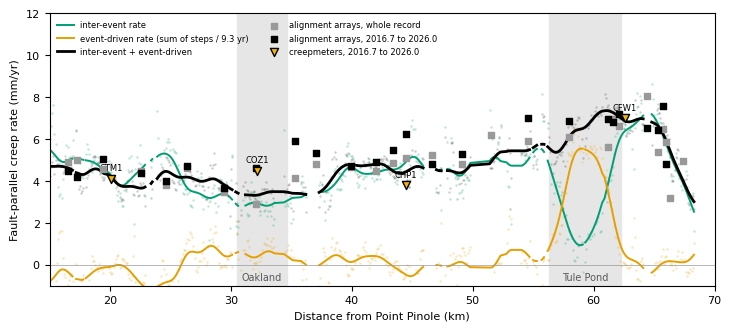

In [15]:
fig, ax = plt.subplots(figsize=(7.2, 3.2), constrained_layout=True)
for name, (lo, hi) in (("Tule Pond", (len_lo, len_hi)), ("Oakland", (c_lo, c_hi))):
    ax.axvspan(lo, hi, color="0.9", zorder=0); ax.text(0.5 * (lo + hi), -0.75, name, ha="center", fontsize=7, color="0.35")
ax.scatter(bud.km, bud.secular, s=3, color=teal, alpha=0.25, lw=0)
ax.scatter(bud.km, bud.event_rate, s=3, color=orange, alpha=0.25, lw=0)
ax.scatter(bud.km, bud.total, s=3, color="k", alpha=0.2, lw=0)
ax.plot(bud.km, bud.secular_smooth, color=teal, lw=1.4, label="inter-event rate")
ax.plot(bud.km, bud.event_rate_smooth, color=orange, lw=1.4, label=f"event-driven rate (sum of steps / {span:.1f} yr)")
ax.plot(bud.km, bud.total_smooth, color="k", lw=2.0, label="inter-event + event-driven")
ax.scatter(aa_df.km, aa_df.rate_longterm, marker="s", s=14, color="0.6", zorder=4, label="alignment arrays, whole record")
ax.scatter(aa_df.km, aa_df.rate_window, marker="s", s=14, color="k", zorder=5, label=f"alignment arrays, {t0:.1f} to {t1:.1f}")
ax.scatter([v[0] for v in cm_rates.values()], [v[1] for v in cm_rates.values()], marker="v", s=34, facecolor="#F5B400",
           edgecolor="k", zorder=6, label=f"creepmeters, {t0:.1f} to {t1:.1f}")
for code, (k_, r_) in cm_rates.items():
    ax.annotate(code, (k_, r_), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=6)
ax.set_xlim(*km_lim); ax.set_ylim(-1, 12); ax.axhline(0, color="0.6", lw=0.5)
ax.set_xlabel("Distance from Point Pinole (km)"); ax.set_ylabel("Fault-parallel creep rate (mm/yr)")
ax.legend(fontsize=6, loc="upper left", ncol=2, frameon=False)
f_bud = os.path.join(fig_dir, f"figS_slip_budget_{params}.png")
fig.savefig(f_bud, dpi=300); fig.savefig(f_bud.replace(".png", ".pdf")); print("Saved figure to:", f_bud)
plt.show()

## REGISTER

In [16]:
L = ["04 EVENT DETECTION", f"stream {params}; stack +/-{stack_half_km:g} km of the section centre; matched filter {win_n} epochs, "
     f"{k_sigma:g} sigma; joint model linear + annual + steps; {nboot} block bootstraps (~{block_years:g} yr blocks)", ""]
for key_, sol in solutions.items():
    L.append(f"[{segments[key_]['label']}] stack n = {sol['n']}, rate {sol['coef'][1]:.2f} mm/yr, annual {np.hypot(sol['coef'][2], sol['coef'][3]):.2f} mm, "
             f"rms {np.sqrt(sol['rss'] / len(sol['series'][0])):.2f} mm")
    for f_ in sol["fits"]:
        L.append(f"   onset {f_['onset_yr']:.4f} [{f_['onset_lo']:.4f}, {f_['onset_hi']:.4f}] amp {f_['amplitude_mm']:.2f} [{f_['amp_lo']:.2f}, {f_['amp_hi']:.2f}] mm")
L += ["", "event-driven fraction (crossings within 2 km of the section centre):"]
for key_, s_ in frac_stats.items():
    L.append(f"   {segments[key_]['label']}: n {s_['n']}, summed slip median {s_['sum_median']:.1f} mm, fraction median {s_['median']:.0f}%, 5-95% {s_['p5']:.0f} to {s_['p95']:.0f}%")
L += ["", f"window {w_lo:.1f} to {w_hi:.1f} km (re-centred on the cumulative-slip peak at {c_new:.1f} km); median inter-event rate in the window {bg_rate:.2f} mm/yr",
      f"cumulative event slip peak {peak_cum:.1f} mm; flank threshold {thr:.2f} mm (median {flank_median:.2f} + 3 x {flank_sigma:.2f})",
      f"length hosting the events: {len_lo:.1f} to {len_hi:.1f} km ({len_hi - len_lo:.1f} km, {len_n} crossings); "
      f"10%: {lengths['10pct'][1] - lengths['10pct'][0]:.1f} km; 20%: {lengths['20pct'][1] - lengths['20pct'][0]:.1f} km",
      f"fraction peak {peak_frac:.1f}%"]
for bf, (lo_km, hi_km, n_) in bands.items():
    r_ = band_res[bf]
    L += [f"band {100 * bf:.0f}%: {lo_km:.1f} to {hi_km:.1f} km ({hi_km - lo_km:.1f} km, {n_} crossings); secular {r_['secular']:.2f} mm/yr, annual {r_['annual']:.2f} mm, rms {r_['rms']:.2f} mm",
          "   steps: " + ", ".join(f"{on:.3f} {a_:.2f} [{l_:.2f}, {h_:.2f}]" for on, a_, l_, h_ in zip(onsets_tp, r_["steps"], r_["lo"], r_["hi"])) +
          f"; sum {np.sum(r_['steps']):.1f}, mean {np.mean(r_['steps']):.1f} mm"]
L += ["", "slip budget (mm/yr; arrays within 1 km of the block, refit over the InSAR window / whole record):"]
for k_, b_ in budget.items():
    L.append(f"   {b_['name']}: {b_['lo']:.1f} to {b_['hi']:.1f} km n {b_['n']}: secular {b_['secular']:.2f}, event {b_['event_rate']:.2f}, "
             f"total {b_['total']:.2f} ({b_['frac_pct']:.0f}%), arrays window {b_['aa_window_mean']:.2f} (n {b_['aa_window_n']}), long-term {b_['aa_longterm_mean']:.2f} (n {b_['aa_n']})")
L += ["", "recurrence intervals (yr): " + ", ".join(f"{x:.2f}" for x in intervals) +
      f"; mean {intervals.mean():.2f}, sd {intervals.std(ddof=1) * 365.25:.0f} d, CoV {intervals.std(ddof=1) / intervals.mean():.2f}",
      f"seismicity (GrowClust) within {seis_max_dist_km:g} km, window {w_lo:.0f}-{w_hi:.0f} km: {n_seis_win} earthquakes, {n_cre_win} repeaters, {n_cre_band} repeaters in the 75% band",
      f"hovmoller colour scale {vmin:.0f} to {vmax:.0f} mm"]
sidecar = REG.sidecar("04_events", L)

REG.register("04_n_events", len(tp), "count", 0, where="P3, abstract", cell="detect", sidecar=sidecar)
REG.register("04_detect_sigma_mm", float(tp.detect_sigma_mm[0]), "mm", 3, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_threshold_mm", k_sigma * float(tp.detect_sigma_mm[0]), "mm", 2, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_stack_n_crossings", solutions["TULEPOND"]["n"], "count", 0, where="M5", cell="detect", sidecar=sidecar)
labels = [f"{int(on)}" for on in onsets_tp]
for lab, (_, r_) in zip(labels, tp.iterrows()):
    REG.register(f"04_onset_{lab}", r_.onset_yr, "decyear", 3, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_lo_{lab}", r_.onset_lo, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_hi_{lab}", r_.onset_hi, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_window_days_{lab}", r_.onset_window_days, "d", 0, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_stack_amp_{lab}_mm", r_.amplitude_mm, "mm", 2, where="M5", cell="joint-fit", sidecar=sidecar)
for bf, (lo_km, hi_km, n_) in bands.items():
    r_ = band_res[bf]; tag = f"band{int(bf * 100)}"
    REG.register(f"04_{tag}_lo_km", lo_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_hi_km", hi_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_width_km", hi_km - lo_km, "km", 1, where="P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_n_crossings", n_, "count", 0, where="Fig1 caption", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_inter_event_mm_yr", r_["secular"], "mm/yr", 2, where="P4, Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_annual_mm", r_["annual"], "mm", 2, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_sum_mm", float(np.sum(r_["steps"])), "mm", 1, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_mean_mm", float(np.mean(r_["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_min_mm", float(np.min(r_["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_max_mm", float(np.max(r_["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    for lab, a_, l_, h_ in zip(labels, r_["steps"], r_["lo"], r_["hi"]):
        REG.register(f"04_{tag}_step_{lab}_mm", a_, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{lab}_ci_lo", l_, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{lab}_ci_hi", h_, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
REG.register("04_creep_length_km", len_hi - len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_lo_km", len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_hi_km", len_hi, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_n_crossings", len_n, "count", 0, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_threshold_mm", thr, "mm", 2, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_10pct_km", lengths["10pct"][1] - lengths["10pct"][0], "km", 1, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_20pct_km", lengths["20pct"][1] - lengths["20pct"][0], "km", 1, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_fraction_peak_pct", peak_frac, "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_median_pct", frac_stats["TULEPOND"]["median"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p5_pct", frac_stats["TULEPOND"]["p5"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p95_pct", frac_stats["TULEPOND"]["p95"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_event_slip_sum_median_mm", frac_stats["TULEPOND"]["sum_median"], "mm", 1, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_hovmoller_bg_rate_mm_yr", bg_rate, "mm/yr", 1, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
REG.register("04_hovmoller_vmax_mm", vmax, "mm", 0, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
for k_, b_ in budget.items():
    for q_ in ("secular", "event_rate", "total"):
        REG.register(f"04_budget_{k_}_{q_.replace('secular', 'inter_event')}_mm_yr", b_[q_], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{k_}_event_pct", b_["frac_pct"], "pct", 0, where="P4", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{k_}_aa_window_mm_yr", b_["aa_window_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{k_}_aa_longterm_mm_yr", b_["aa_longterm_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{k_}_aa_n", b_["aa_n"], "count", 0, where="Fig1 caption", cell="budget", sidecar=sidecar)
REG.register("04_record_span_yr", span, "yr", 2, where="Fig1 caption", cell="budget", sidecar=sidecar)
REG.register_many("04_interval_yr", list(intervals), "yr", 2, where="P9", cell="intervals", labels=[f"{int(a)}_{int(b)}" for a, b in zip(onsets_tp[:-1], onsets_tp[1:])], sidecar=sidecar)
REG.register("04_interval_mean_yr", intervals.mean(), "yr", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("04_interval_sd_d", intervals.std(ddof=1) * 365.25, "d", 0, where="P9", cell="intervals", sidecar=sidecar)
REG.register("04_interval_cov", intervals.std(ddof=1) / intervals.mean(), "1", 2, where="P9", cell="intervals", sidecar=sidecar)
REG.register("04_n_seis_window", n_seis_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_window", n_cre_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_band", n_cre_band, "count", 0, where="P3", cell="catalogues", sidecar=sidecar)
for lab, r_ in zip(["2019", "2022", "2024"], ev[ev.segment == "COZ1"].itertuples()):
    REG.register(f"04_control_coz1_onset_{lab}", r_.onset_yr, "decyear", 3, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_amp_{lab}_mm", r_.amplitude_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_creepmeter_{lab}_mm", r_.creepmeter_step_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/04_event_detection/04_events_stats.txt
  registered 04_n_events = 5 count  -> P3, abstract
  registered 04_detect_sigma_mm = 0.808 mm  -> M5
  registered 04_threshold_mm = 2.42 mm  -> M5
  registered 04_stack_n_crossings = 45 count  -> M5
  registered 04_onset_2017 = 2017.099 decyear  -> P3
  registered 04_onset_lo_2017 = 2017.0822 decyear  -> P3
  registered 04_onset_hi_2017 = 2017.0986 decyear  -> P3
  registered 04_onset_window_days_2017 = 6 d  -> P3
  registered 04_stack_amp_2017_mm = 9.11 mm  -> M5
  registered 04_onset_2019 = 2019.186 decyear  -> P3


  registered 04_onset_lo_2019 = 2019.1699 decyear  -> P3
  registered 04_onset_hi_2019 = 2019.1863 decyear  -> P3
  registered 04_onset_window_days_2019 = 6 d  -> P3
  registered 04_stack_amp_2019_mm = 9.12 mm  -> M5
  registered 04_onset_2021 = 2021.107 decyear  -> P3
  registered 04_onset_lo_2021 = 2021.0904 decyear  -> P3


  registered 04_onset_hi_2021 = 2021.1068 decyear  -> P3
  registered 04_onset_window_days_2021 = 6 d  -> P3
  registered 04_stack_amp_2021_mm = 8.33 mm  -> M5
  registered 04_onset_2023 = 2023.080 decyear  -> P3
  registered 04_onset_lo_2023 = 2023.0466 decyear  -> P3
  registered 04_onset_hi_2023 = 2023.0795 decyear  -> P3
  registered 04_onset_window_days_2023 = 12 d  -> P3
  registered 04_stack_amp_2023_mm = 8.79 mm  -> M5
  registered 04_onset_2024 = 2024.984 decyear  -> P3
  registered 04_onset_lo_2024 = 2024.9508 decyear  -> P3
  registered 04_onset_hi_2024 = 2024.9836 decyear  -> P3
  registered 04_onset_window_days_2024 = 12 d  -> P3


  registered 04_stack_amp_2024_mm = 6.62 mm  -> M5
  registered 04_band75_lo_km = 57.8 km  -> Fig1 caption, P3
  registered 04_band75_hi_km = 60.5 km  -> Fig1 caption, P3
  registered 04_band75_width_km = 2.7 km  -> P3
  registered 04_band75_n_crossings = 28 count  -> Fig1 caption


  registered 04_band75_inter_event_mm_yr = 1.24 mm/yr  -> P4, Fig1 caption
  registered 04_band75_annual_mm = 0.63 mm  -> Fig1 caption
  registered 04_band75_steps_sum_mm = 50.6 mm  -> Fig1 caption
  registered 04_band75_steps_mean_mm = 10.1 mm  -> P3
  registered 04_band75_steps_min_mm = 7.8 mm  -> P3
  registered 04_band75_steps_max_mm = 10.9 mm  -> P3
  registered 04_band75_step_2017_mm = 10.91 mm  -> P3
  registered 04_band75_step_2017_ci_lo = 9.71 mm  -> P3
  registered 04_band75_step_2017_ci_hi = 11.98 mm  -> P3
  registered 04_band75_step_2019_mm = 10.47 mm  -> P3
  registered 04_band75_step_2019_ci_lo = 9.36 mm  -> P3


  registered 04_band75_step_2019_ci_hi = 11.45 mm  -> P3
  registered 04_band75_step_2021_mm = 10.47 mm  -> P3


... (10 outputs left out)

  registered 04_budget_coz1_total_mm_yr = 3.35 mm/yr  -> P4, Fig1c
  registered 04_budget_coz1_event_pct = 15 pct  -> P4
  registered 04_budget_coz1_aa_window_mm_yr = 5.27 mm/yr  -> P4, Fig1c
  registered 04_budget_coz1_aa_longterm_mm_yr = 3.51 mm/yr  -> P4, Fig1c
  registered 04_budget_coz1_aa_n = 2 count  -> Fig1 caption
  registered 04_record_span_yr = 9.28 yr  -> Fig1 caption
  registered 04_interval_yr_2017_2019 = 2.09 yr  -> P9
  registered 04_interval_yr_2019_2021 = 1.92 yr  -> P9
  registered 04_interval_yr_2021_2023 = 1.97 yr  -> P9
  registered 04_interval_yr_2023_2024 = 1.90 yr  -> P9
  registered 04_interval_mean_yr = 1.97 yr  -> P9
  registered 04_interval_sd_d = 30 d  -> P9
  registered 04_interval_cov = 0.04 1  -> P9


  registered 04_n_seis_window = 234 count  -> Fig1 caption
  registered 04_n_cre_window = 18 count  -> Fig1 caption
  registered 04_n_cre_band = 0 count  -> P3


  registered 04_control_coz1_onset_2019 = 2019.022 decyear  -> M5 (control)
  registered 04_control_coz1_amp_2019_mm = 2.17 mm  -> M5 (control)
  registered 04_control_coz1_creepmeter_2019_mm = 3.75 mm  -> M5 (control)
  registered 04_control_coz1_onset_2022 = 2022.126 decyear  -> M5 (control)
  registered 04_control_coz1_amp_2022_mm = 4.59 mm  -> M5 (control)
  registered 04_control_coz1_creepmeter_2022_mm = 7.14 mm  -> M5 (control)
Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'